# Lab 02 — Transfer learning và đánh giá

ResNet18 / DenseNet121; head-only → fine-tune một/hai block cuối. [EDA](01_lab02_eda.ipynb) · [Báo cáo](../walkthrough_lab_02.md) · [Cấu hình run cũ](../config/cpu_full.json)

In [1]:
from pathlib import Path
import os, sys
ROOT = next(p for p in [Path(os.getenv('LAB02_ROOT', '.')).resolve(), *Path.cwd().resolve().parents] if (p / 'src/eda.py').exists())
sys.path.insert(0, str(ROOT))
from src import notebook_views as view
ROOT, RUN, OUT = view.context()
print('Run đã lưu:', RUN.name)

Run đã lưu: 20261024T075133Z_cifar10_cpu_full64_71863a0e


## 1. Kiến trúc và freeze/unfreeze

Classifier đổi thành 10 đầu ra. Biểu đồ so sánh tham số được học; mở phần thu gọn để xem đầy đủ cấu trúc đã lưu. [Source](../src/models.py).

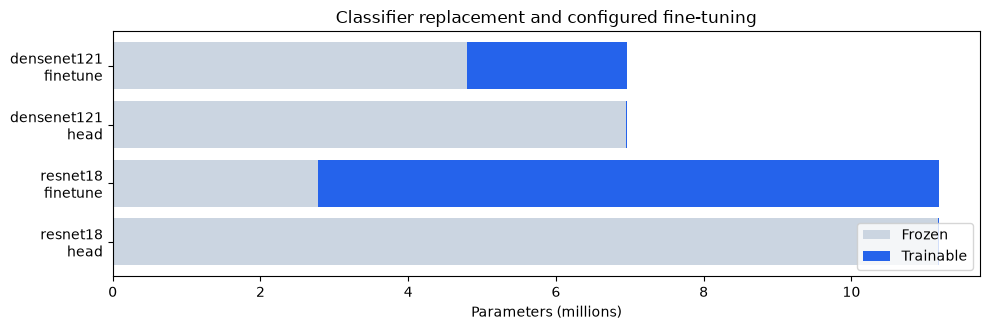

,model,stage,total,trainable,unfrozen_blocks
0,resnet18,head,11181642,5130,classifier
1,resnet18,finetune,11181642,8398858,layer4 + fc
2,densenet121,head,6964106,10250,classifier
3,densenet121,finetune,6964106,2170378,denseblock4 + norm5 + classifier


In [2]:
view.architecture_visual(RUN, OUT)

## 2. Learning rate × batch size

Grid head đã chạy; chọn candidate bằng validation theo policy của run. Notebook không dùng test để chọn cấu hình.

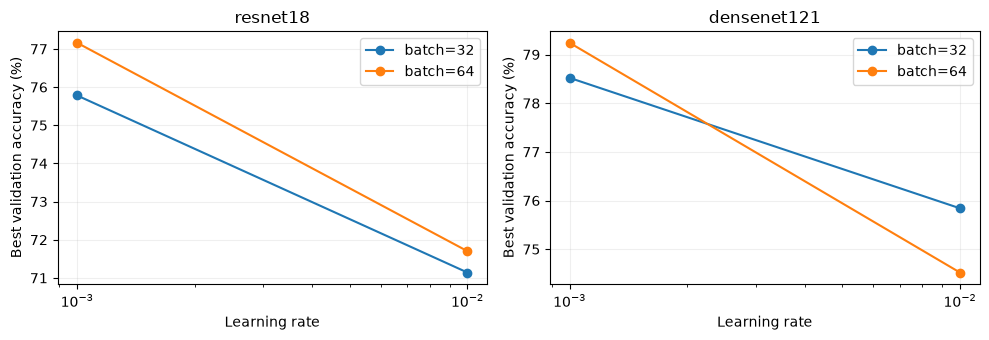

In [3]:
view.lr_search(RUN, OUT)

### Fine-tune: LR, optimizer và độ sâu

Grid mới có thể chạy bằng `config/tuned.json`: AdamW/SGD momentum, LR riêng cho backbone/head, một/hai block cuối và cosine scheduler. Nếu run chưa có search, biểu đồ ghi rõ kế hoạch chưa chạy.

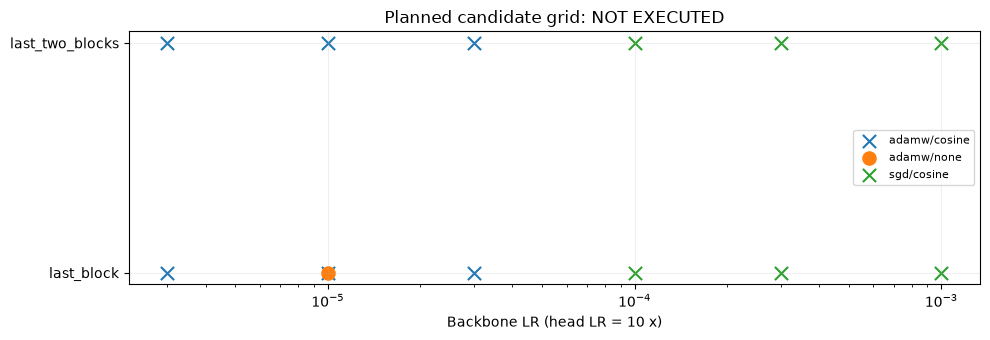

In [4]:
view.fine_search(RUN, OUT, ROOT)

## 3. Đường cong học

Nét đứt: head; nét liền: fine-tune. Epoch bắt đầu lại theo giai đoạn. Run lịch sử chỉ có 2 epoch fine-tune; xem cấu hình và đường cong để đánh giá hội tụ.

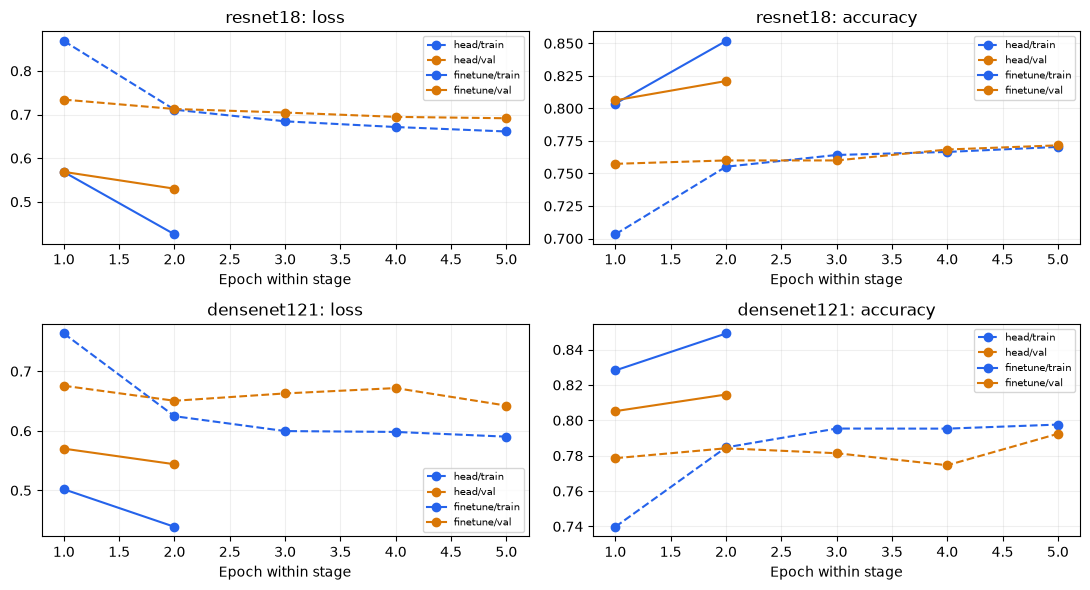

In [5]:
view.learning_curves(RUN, OUT)

## 4. Chất lượng và chi phí

Đọc cùng accuracy, loss, Macro F1 và thời gian. Phân biệt toàn bộ search với selected recipe. Chỉ dùng thời gian để xếp hạng khi chính sách thực thi tương ứng; run lịch sử có cache khác nhau.

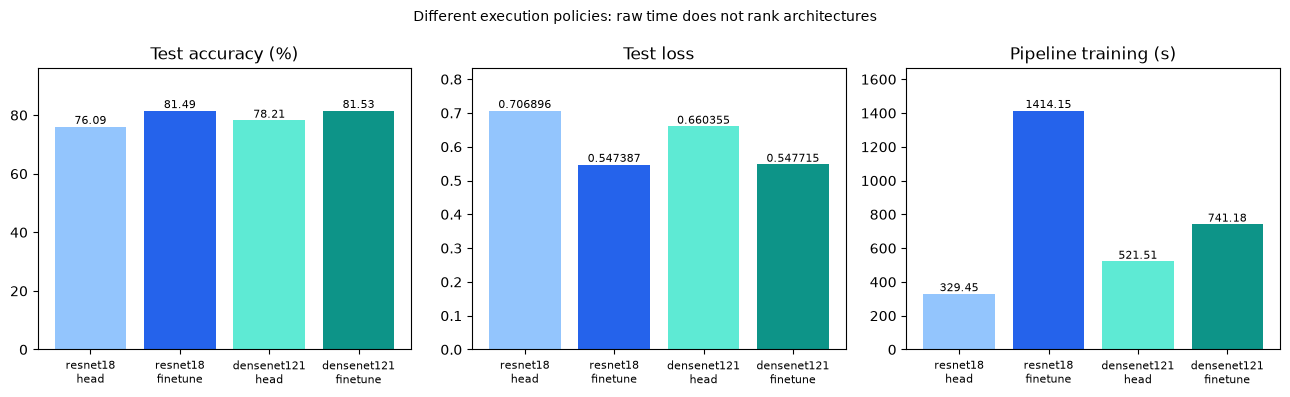

,model,stage,accuracy,loss,macro_f1,best_val_accuracy,train_seconds,pipeline_training_seconds,test_seconds,execution
0,resnet18,head,0.7609,0.7069,0.7611,0.7716,8.8886,329.4474,64.0027,pooled_feature_cache
1,resnet18,finetune,0.8149,0.5474,0.8146,0.8210,1084.6990,1414.1464,62.7633,full_image_forward
2,densenet121,head,0.7821,0.6604,0.7811,0.7924,8.9819,521.5133,100.4044,pooled_feature_cache
3,densenet121,finetune,0.8153,0.5477,0.8151,0.8146,219.6618,741.1751,92.3854,cached_frozen_prefix


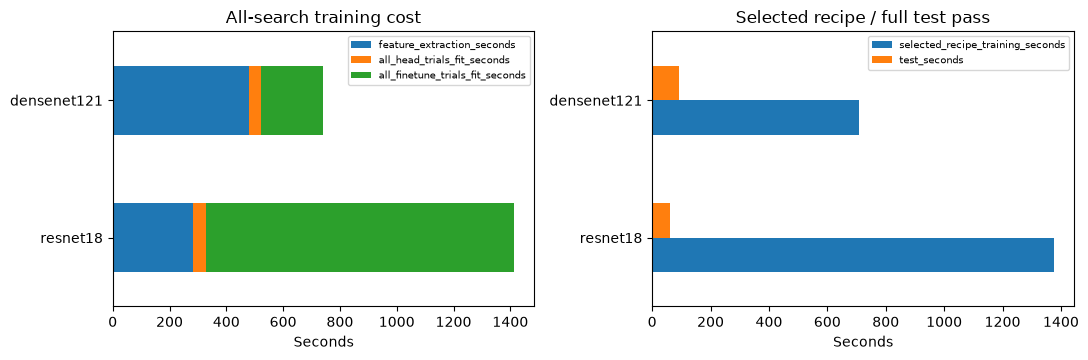

,model,execution,pipeline_training_seconds,selected_recipe_training_seconds,test_seconds
1,resnet18,full_image_forward,1414.15,1375.44,62.76
3,densenet121,cached_frozen_prefix,741.18,706.75,92.39


,model,val_accuracy,val_loss,time_comparable
0,resnet18,0.821,0.530082,False


In [6]:
view.quality_cost(RUN, OUT)
view.efficiency(RUN, OUT)

## 5. Phân tích lỗi theo lớp

Heatmap phủ precision, recall/TPR, F1 và FPR. Bảng CSV giữ toàn bộ lớp; notebook chỉ hiển thị các lớp F1 thấp nhất.

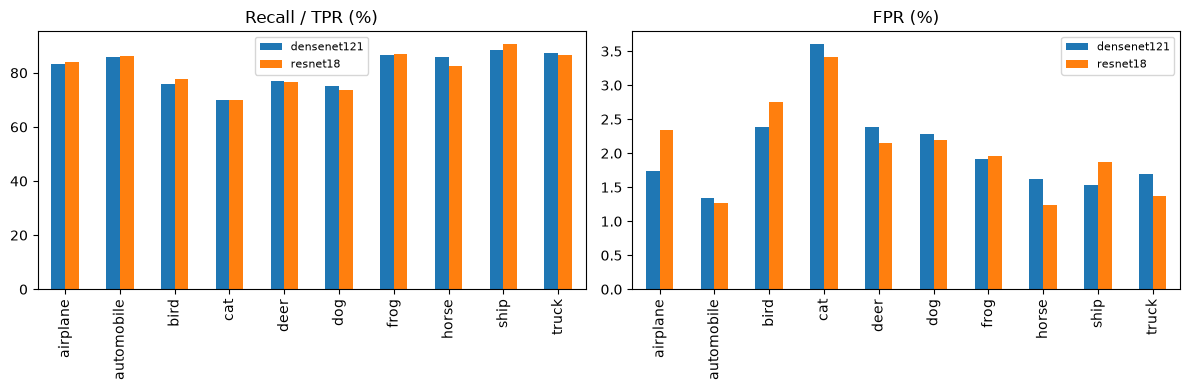

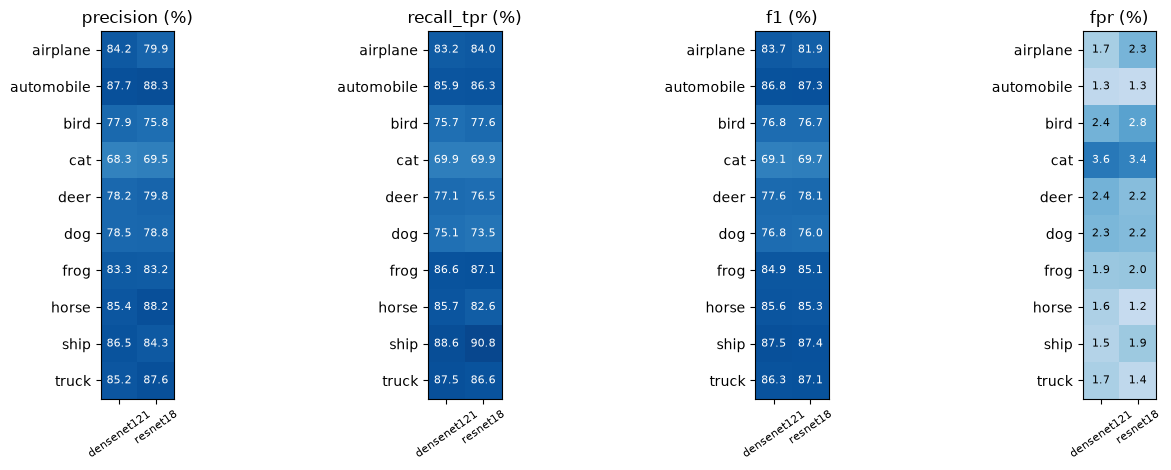

,model,stage,class,precision,recall_tpr,f1,fpr
33,densenet121,finetune,cat,0.6826,0.699,0.6907,0.0361
13,resnet18,finetune,cat,0.6948,0.699,0.6969,0.0341
15,resnet18,finetune,dog,0.7878,0.735,0.7605,0.0220
35,densenet121,finetune,dog,0.7847,0.751,0.7675,0.0229


In [7]:
view.errors(RUN, OUT)

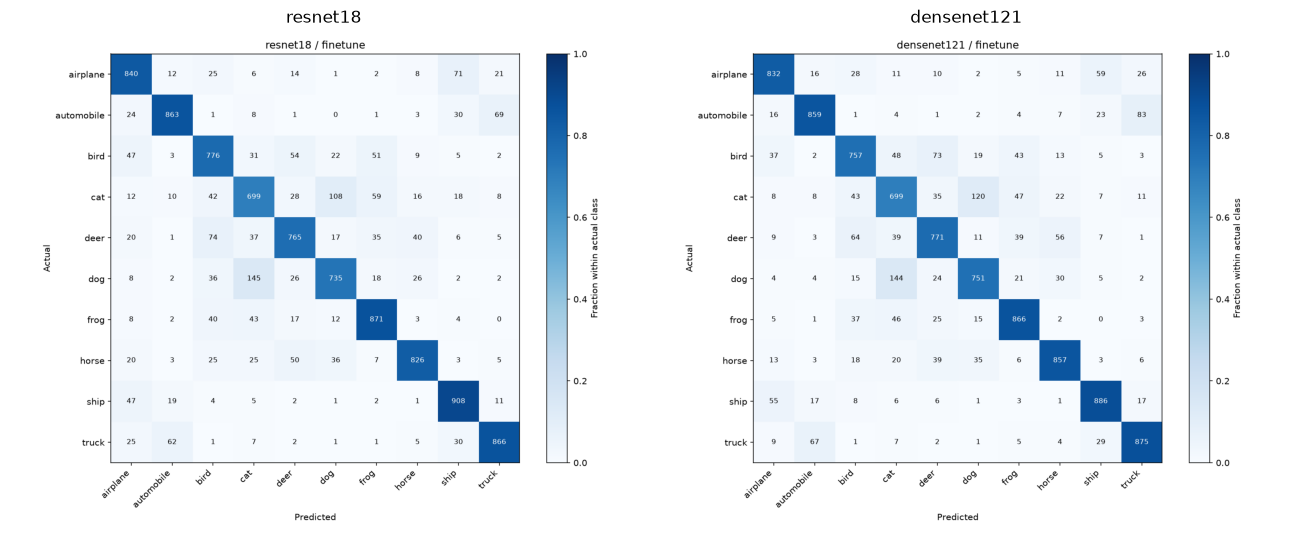

In [8]:
view.evidence(RUN, 'confusion_matrix')

Đọc confusion matrix theo hàng nhãn thật; bảng phía trên chỉ ra lớp yếu của run đang xem. Lưới dưới chọn tối đa 8 đúng và 8 sai để minh họa, không đại diện accuracy.

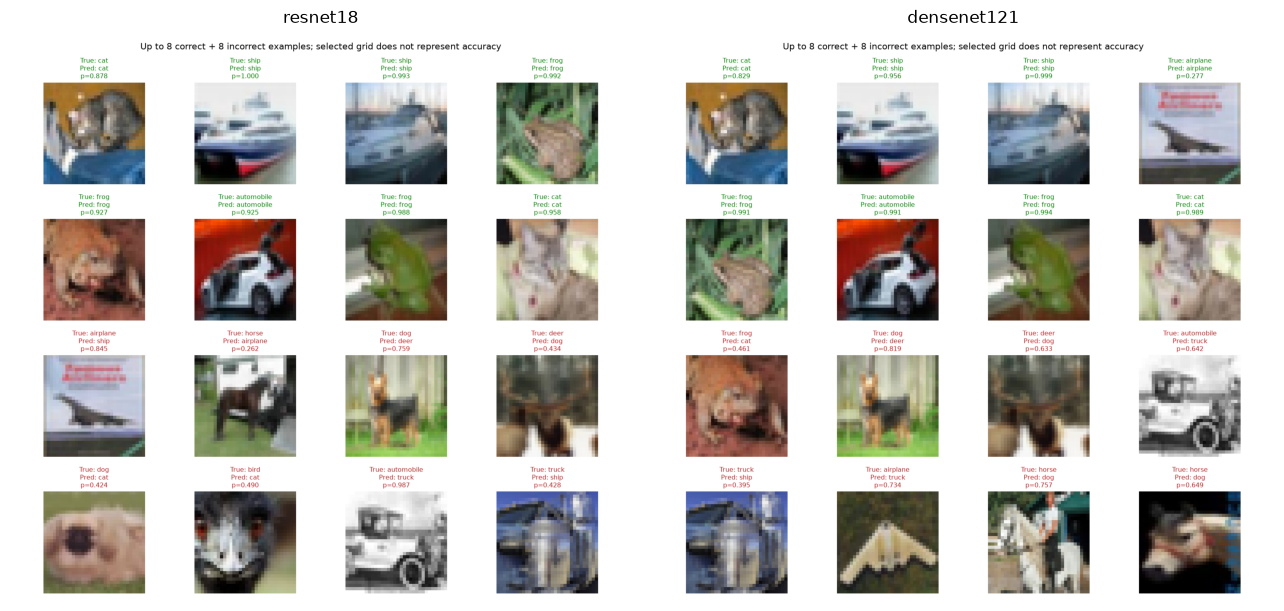

In [9]:
view.evidence(RUN, 'prediction_examples')

## 6. TensorBoard

Hình dựng từ scalar events đã lưu, không phải ảnh chụp giao diện. Mở tương tác bằng `tensorboard --logdir outputs/runs` khi có event files gốc.

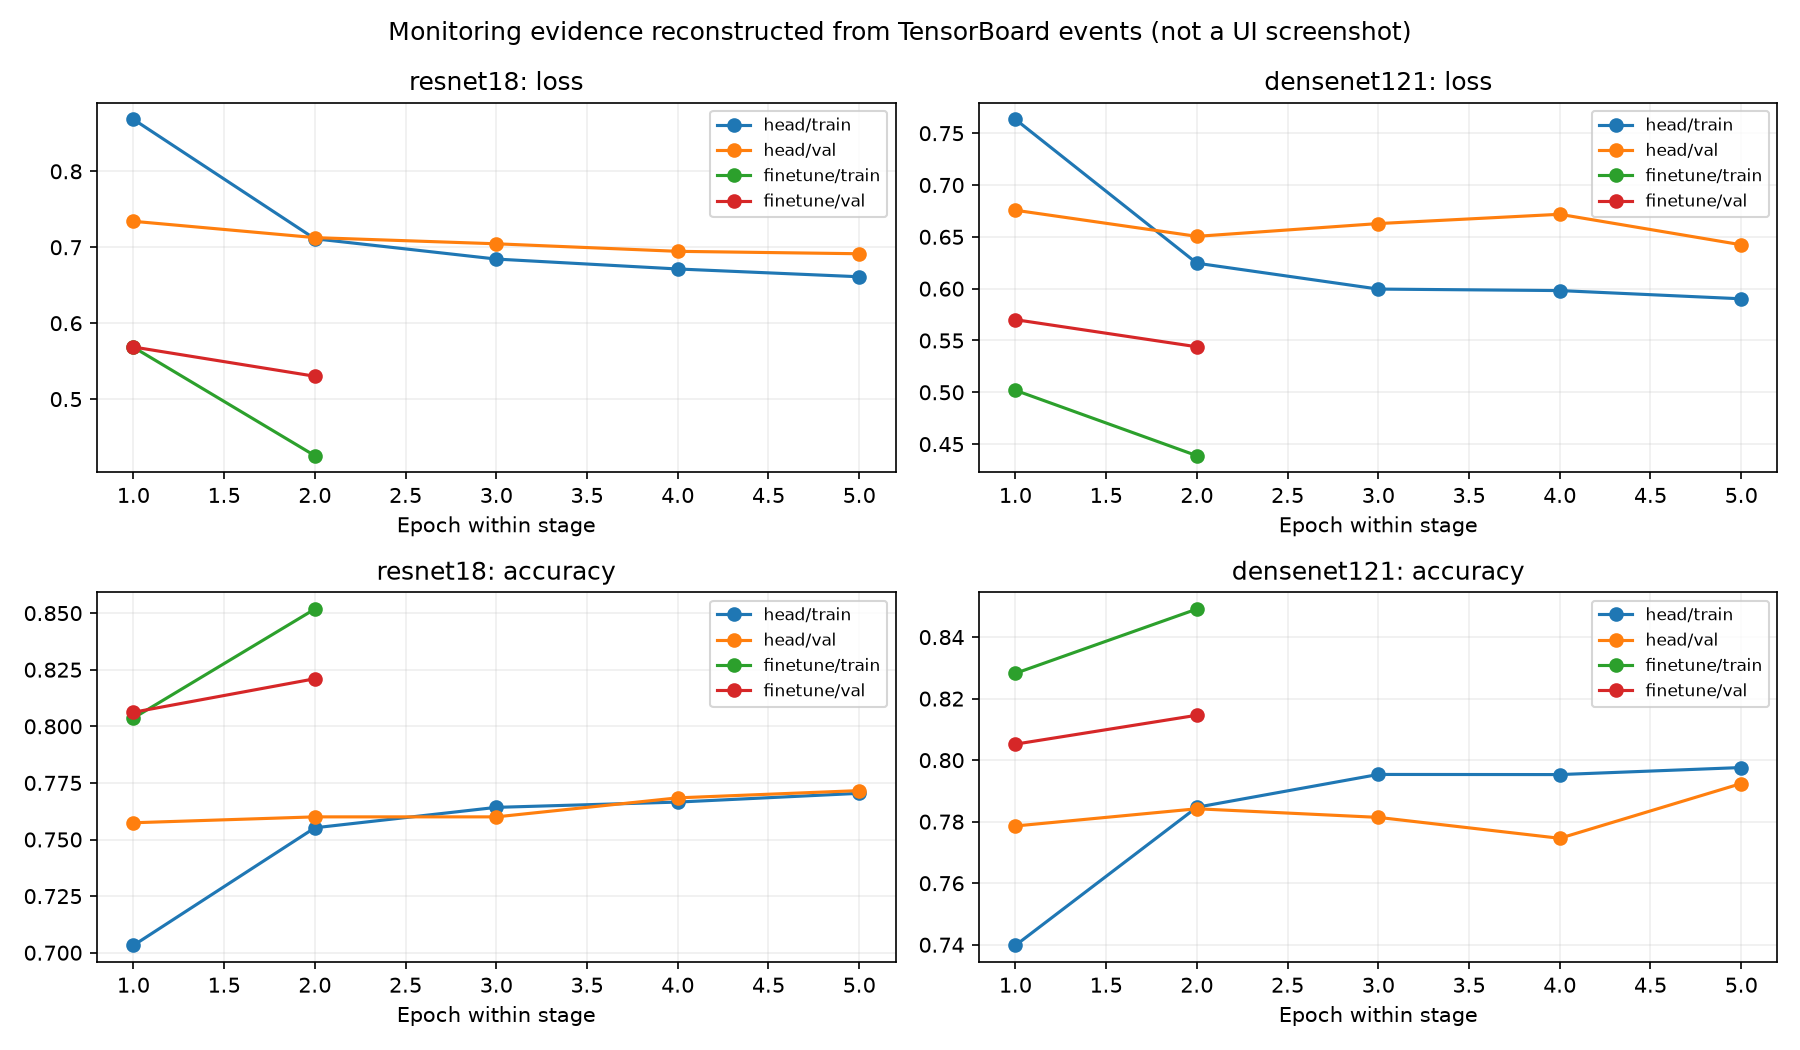

In [10]:
view.tensorboard_evidence(RUN)

## 7. Save/load và kết luận

Bảng kiểm chứng đã lưu trên 8 mẫu mỗi điều kiện; không thực hiện inference mới. Khuyến nghị theo validation và điều kiện so sánh thời gian nằm ở mục 4.

In [11]:
view.roundtrip(RUN)

,model,stage,samples,max_probability_error,passed
0,resnet18,head,8,0.0,True
1,resnet18,finetune,8,0.0,True
2,densenet121,head,8,0.0,True
3,densenet121,finetune,8,0.0,True


Tuning GPU: `python scripts/run.py --config config/tuned.json --device cuda`. Xem trước ngân sách bằng `--dry-run`; lặp seed bằng `--seed 43`/`--seed 44`, split vẫn giữ seed 42. [Source training](../src/experiment.py) · [Thiết kế và giới hạn](../walkthrough_lab_02.md#15-loss-function-and-optimization-design).